# OTT Streaming Content Trend Analysis — Netflix Catalog
**Role:** Content strategy analyst · **Question:** What has changed in Netflix's catalog, and what should the acquisition team greenlight next?

**Dataset:** Netflix titles catalog (8,807 titles, 12 columns, titles added 2008–2021).
**Notebook flow:** 1) Load & audit → 2) Clean → 3) EDA (10 visualizations) → 4) Insights for the content acquisition team.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os
os.makedirs('../images', exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RED, GREY = '#E50914', '#6b6b6b'
PAL = {'Movie': '#B20710', 'TV Show': '#4a4a4a'}

def save(name):
    plt.tight_layout(); plt.savefig(f'../images/{name}.png', dpi=150, bbox_inches='tight')

## 1. Load & audit the raw data

In [2]:
raw = pd.read_csv('../data/netflix_titles_raw.csv')
print(raw.shape)
display(raw.head(3))
audit = pd.DataFrame({'nulls': raw.isna().sum(), 'null_%': (raw.isna().mean()*100).round(1), 'dtype': raw.dtypes.astype(str)})
audit

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


,nulls,null_%,dtype
show_id,0,0.0,str
type,0,0.0,str
title,0,0.0,str
director,2634,29.9,str
cast,825,9.4,str
country,831,9.4,str
date_added,10,0.1,str
release_year,0,0.0,int64
rating,4,0.0,str
duration,3,0.0,str


**Audit findings**
- `director` (29.9% null), `country` (9.4%), `cast` (9.4%) have the most gaps. Director is too sparse to base strategy on, so the analysis centres on genre, country, rating, duration and dates.
- `date_added` (10), `rating` (4), `duration` (3) have small gaps.
- **Data-quality bug:** 3 rows have a duration string (e.g. `74 min`) stored in the `rating` column and a null `duration` — a column-shift error. Fixed below.
- `listed_in` and `country` are multi-valued (comma separated) → need to be exploded for genre/country counts.

In [3]:
print('Duplicate rows:', raw.duplicated().sum(), '| duplicate show_id:', raw.show_id.duplicated().sum())
print('Rows where rating looks like a duration:', raw.rating.str.contains('min', na=False).sum())
print(raw[raw.rating.str.contains('min', na=False)][['title','rating','duration']])

Duplicate rows: 0 | duplicate show_id: 0
Rows where rating looks like a duration: 3
                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN


## 2. Cleaning & feature engineering
The full pipeline lives in `clean.py` (reproducible). Steps are repeated here so the notebook is self-contained.

In [4]:
df = raw.copy()
for c in df.select_dtypes(include=['object','string']): df[c] = df[c].str.strip()

# 1) fix shifted rows
mis = df['rating'].str.contains('min', na=False)
df.loc[mis, 'duration'] = df.loc[mis, 'rating']; df.loc[mis, 'rating'] = np.nan

# 2) dates
df['date_added'] = pd.to_datetime(df['date_added'], format='%B %d, %Y', errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['lag_years']  = df['year_added'] - df['release_year']      # release -> Netflix delay

# 3) duration -> numeric
d = df['duration'].str.extract(r'(\d+)\s*(min|Season)')
df['duration_num'] = pd.to_numeric(d[0])
df['duration_min'] = np.where(df.type=='Movie', df.duration_num, np.nan)
df['n_seasons']    = np.where(df.type=='TV Show', df.duration_num, np.nan)

# 4) missing categoricals
for c in ['director','cast','country']: df[c] = df[c].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')

# 5) rating -> audience
aud = {'TV-Y':'Kids','TV-Y7':'Kids','TV-Y7-FV':'Kids','TV-G':'Kids','G':'Kids',
       'TV-PG':'Teens','PG':'Teens','TV-14':'Teens','PG-13':'Teens',
       'TV-MA':'Adults','R':'Adults','NC-17':'Adults','NR':'Unrated','UR':'Unrated','Unknown':'Unrated'}
df['audience'] = df['rating'].map(aud)

# 6) country / genre features
df['primary_country'] = df['country'].str.split(',').str[0].str.strip()
df['n_countries'] = df['country'].apply(lambda s: 0 if s=='Unknown' else len(s.split(',')))
df['is_coprod'] = df['n_countries'] > 1
df['release_era'] = pd.cut(df.release_year, [1900,1999,2009,2014,2017,2019,2021],
                           labels=['Pre-2000','2000-09','2010-14','2015-17','2018-19','2020-21'])

def explode(col, name):
    t = df[['show_id', col]].assign(**{name: df[col].str.split(',')}).explode(name)
    t[name] = t[name].str.strip()
    return t[(t[name]!='') & (t[name]!='Unknown')][['show_id', name]].drop_duplicates()
genres, countries = explode('listed_in','genre'), explode('country','country')
G = genres.merge(df[['show_id','type','release_year','year_added','release_era']], on='show_id')
CT = countries.merge(df[['show_id','type','release_year','year_added']], on='show_id')

print('Clean shape:', df.shape, '| genre rows:', len(genres), '| country rows:', len(countries))
df.isna().sum()[lambda s: s>0]

Clean shape: (8807, 22) | genre rows: 19323 | country rows: 10012


date_added        10
year_added        10
lag_years         10
duration_min    2676
n_seasons       6131
dtype: int64

Remaining nulls are only `date_added` (10 rows) and the intentional `NaN`s in `duration_min` (TV shows) / `n_seasons` (movies). Everything else is filled or fixed. Cleaned file is saved as `data/netflix_titles_clean.csv`.

## 3. Exploratory analysis

### Viz 1 — Catalog composition: Movies vs TV Shows

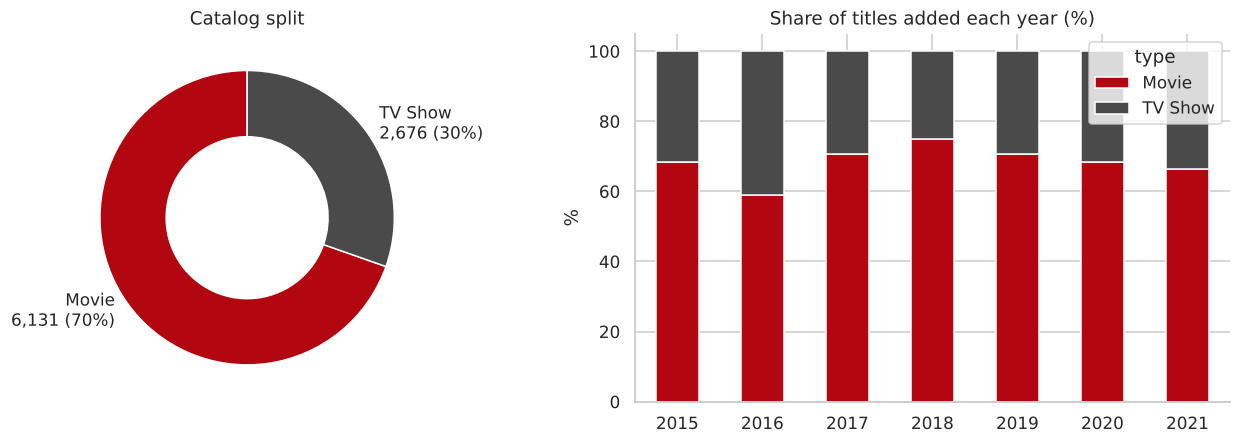

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
tc = df.type.value_counts()
ax[0].pie(tc, labels=[f'{k}\n{v:,} ({v/len(df):.0%})' for k, v in tc.items()],
          colors=[PAL[k] for k in tc.index], startangle=90, wedgeprops={'width':0.45, 'edgecolor':'white'})
ax[0].set_title('Catalog split')
yr = df[df.year_added.between(2015, 2021)].groupby(['year_added','type']).size().unstack()
yr.div(yr.sum(axis=1), axis=0).mul(100).plot(kind='bar', stacked=True, color=[PAL['Movie'], PAL['TV Show']], ax=ax[1], rot=0)
ax[1].set_title('Share of titles added each year (%)'); ax[1].set_xlabel(''); ax[1].set_ylabel('%')
ax[1].set_xticklabels([int(x.get_text().replace('.0','')) for x in ax[1].get_xticklabels()])
save('01_catalog_composition'); plt.show()

**Takeaway:** Movies are ~70% of the catalog, but TV's share of *new additions* has crept up from 25% (2018) to 34% (2021) — Netflix is leaning toward series.

### Viz 2 — Content velocity: titles added per year

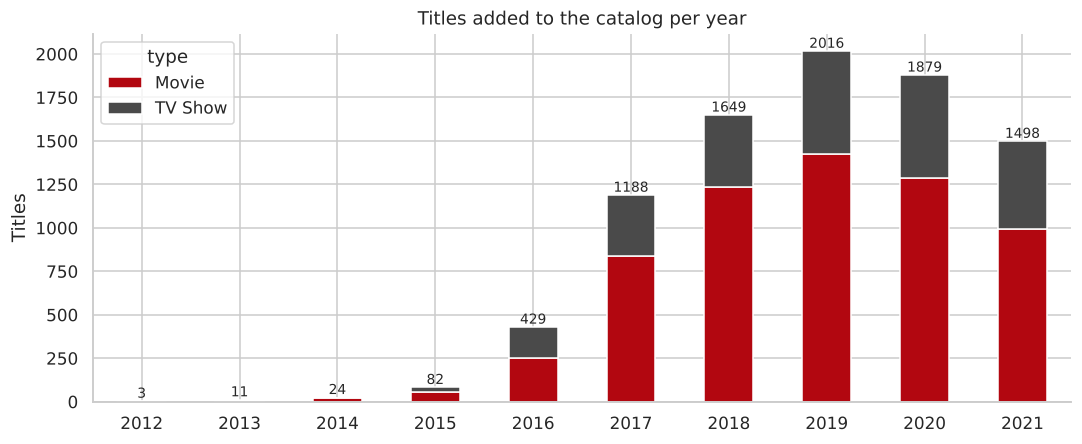

type,Movie,TV Show,total
year_added,,,
2012,3.0,0.0,3.0
2013,6.0,5.0,11.0
2014,19.0,5.0,24.0
2015,56.0,26.0,82.0
2016,253.0,176.0,429.0
2017,839.0,349.0,1188.0
2018,1237.0,412.0,1649.0
2019,1424.0,592.0,2016.0
2020,1284.0,595.0,1879.0


In [6]:
add = df[df.year_added.between(2012, 2021)].groupby(['year_added','type']).size().unstack().fillna(0)
add.index = add.index.astype(int)
ax = add.plot(kind='bar', stacked=True, color=[PAL['Movie'], PAL['TV Show']], figsize=(10, 4.2), rot=0)
ax.set_title('Titles added to the catalog per year'); ax.set_xlabel(''); ax.set_ylabel('Titles')
for i, t in enumerate(add.sum(axis=1)): ax.text(i, t+20, int(t), ha='center', fontsize=9)
save('02_titles_added_per_year'); plt.show()
add.assign(total=add.sum(axis=1))

**Takeaway:** Additions grew ~4.7x between 2016 and 2019 (429 → 2,016), then fell in 2020 (1,879) and 2021 (1,498; partial year — data ends 25 Sep 2021). The land-grab phase is over; growth is now about *selectivity*.

### Viz 3 — Top genres, split by Movies and TV

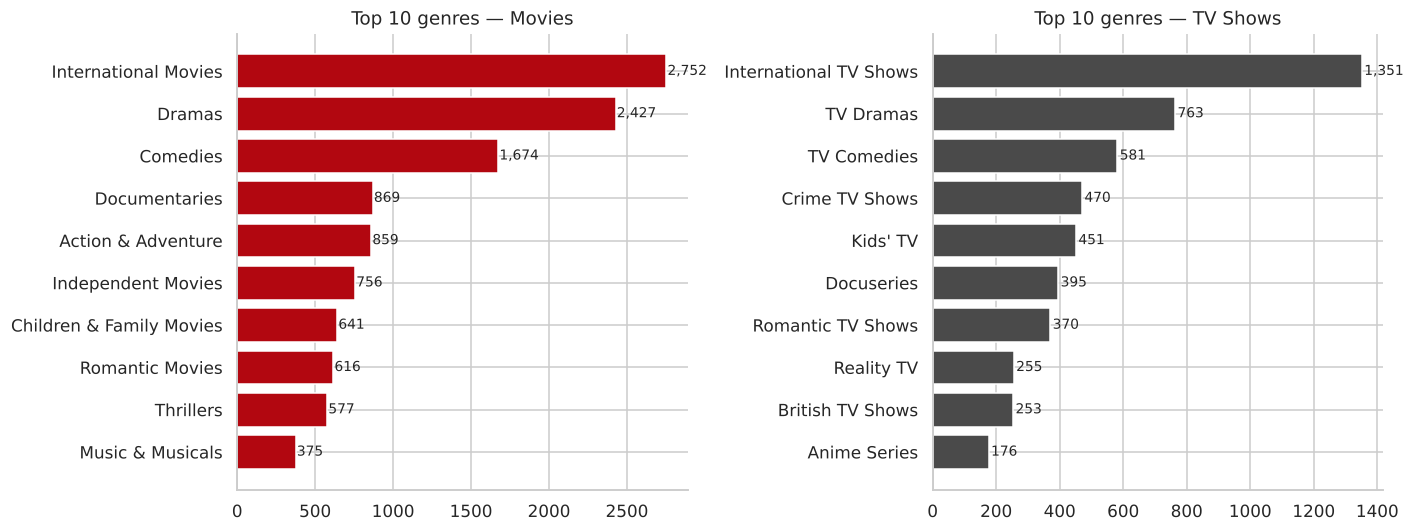

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, t in zip(ax, ['Movie', 'TV Show']):
    top = G[G.type==t].genre.value_counts().head(10).sort_values()
    a.barh(top.index, top.values, color=PAL[t]); a.set_title(f'Top 10 genres — {t}s')
    for i, v in enumerate(top.values): a.text(v+8, i, f'{v:,}', va='center', fontsize=9)
save('03_top_genres'); plt.show()

**Takeaway:** Drama, Comedy and International dominate movies. On TV, *International TV Shows* is #1 and Crime, Kids' and Docuseries are all large — catalog depth is global.

### Viz 4 — Genre mix shift by release era (heatmap)

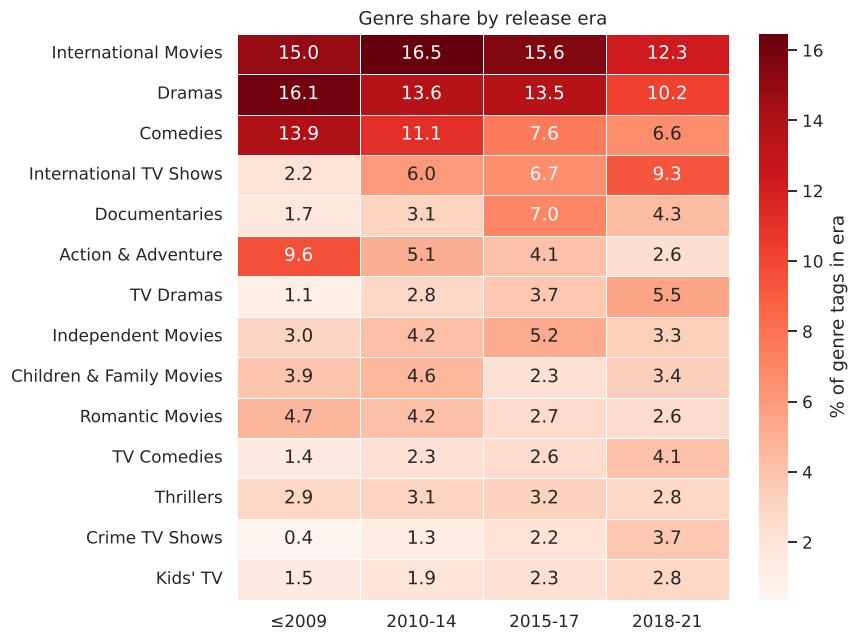

genre
Comedies                   -7.3
Action & Adventure         -7.0
Dramas                     -5.9
International Movies       -2.7
Romantic Movies            -2.1
Children & Family Movies   -0.5
Thrillers                  -0.1
Independent Movies          0.3
Kids' TV                    1.4
Documentaries               2.6
TV Comedies                 2.7
Crime TV Shows              3.4
TV Dramas                   4.5
International TV Shows      7.0
Name: pp change ≤2009 → 2018-21, dtype: float64

In [8]:
G['era2'] = pd.cut(G.release_year, [1900,2009,2014,2017,2021], labels=['≤2009','2010-14','2015-17','2018-21'])
top = G.genre.value_counts().head(14).index
mix = (pd.crosstab(G.era2, G.genre, normalize='index')[top] * 100).T
plt.figure(figsize=(8, 6))
sns.heatmap(mix, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '% of genre tags in era'}, linewidths=.5)
plt.title('Genre share by release era'); plt.ylabel(''); plt.xlabel('')
save('04_genre_mix_by_era'); plt.show()
(mix['2018-21'] - mix['≤2009']).sort_values().round(1).rename('pp change ≤2009 → 2018-21')

**Takeaway:** Comparing 2018-21 releases with ≤2009 releases, TV genres gained share — International TV Shows (+7.0 pp), TV Dramas (+4.5), Crime TV (+3.4), TV Comedies (+2.7), Documentaries (+2.6) — while movie staples lost it: Comedies (−7.3 pp), Action & Adventure (−7.0), Dramas (−5.9). Series formats are where the catalog is growing.

### Viz 5 — Content ratings & audience mix

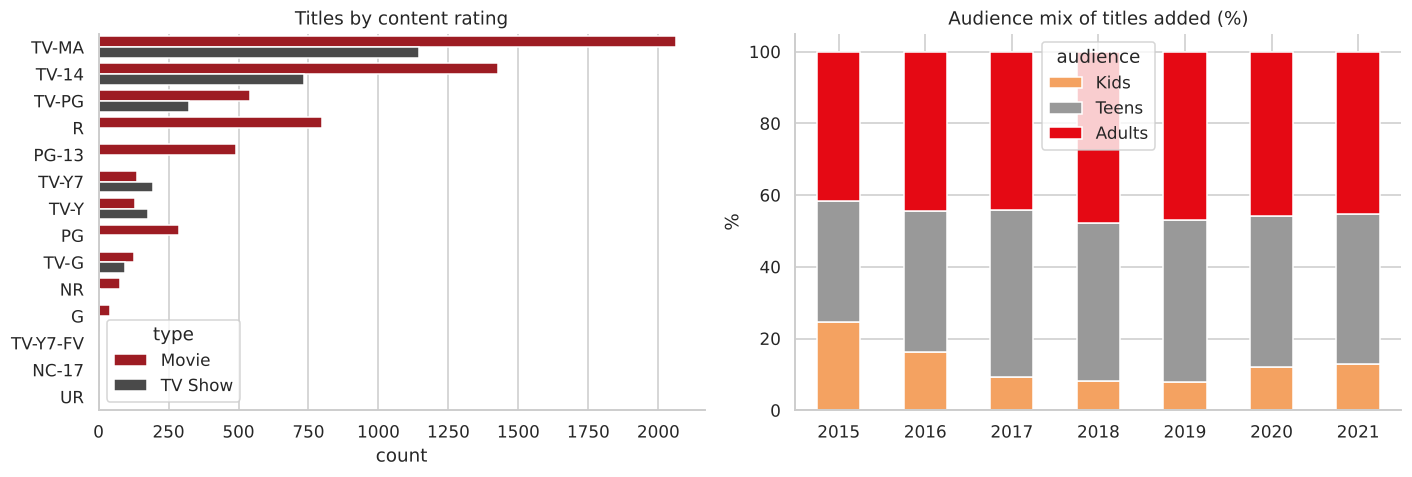

TV-MA + TV-14 share of catalog: 61%


audience,Kids,Teens,Adults
year_added,,,
2015,24.7,33.8,41.6
2016,16.3,39.3,44.4
2017,9.3,46.5,44.2
2018,8.2,44.1,47.7
2019,7.8,45.2,47.0
2020,12.1,42.2,45.7
2021,12.8,41.9,45.3


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
order = df.rating[df.rating!='Unknown'].value_counts().index
sns.countplot(data=df[df.rating!='Unknown'], y='rating', hue='type', order=order, palette=PAL, ax=ax[0])
ax[0].set_title('Titles by content rating'); ax[0].set_ylabel('')
aud = df[df.year_added.between(2015, 2021) & (df.audience!='Unrated')]
a = pd.crosstab(aud.year_added, aud.audience, normalize='index')[['Kids','Teens','Adults']] * 100
a.index = a.index.astype(int)
a.plot(kind='bar', stacked=True, ax=ax[1], color=['#f4a261','#999999',RED], rot=0)
ax[1].set_title('Audience mix of titles added (%)'); ax[1].set_xlabel(''); ax[1].set_ylabel('%')
save('05_ratings_audience'); plt.show()
print('TV-MA + TV-14 share of catalog: {:.0%}'.format(df.rating.isin(['TV-MA','TV-14']).mean()))
a.round(1)

**Takeaway:** TV-MA and TV-14 together make up ~61% of the catalog; Adult-rated content is the single largest slice. Kids' content is only 7% of movies but 17% of TV shows — kids' *series* are the more developed lane.

### Viz 6 — Regional content mix over time

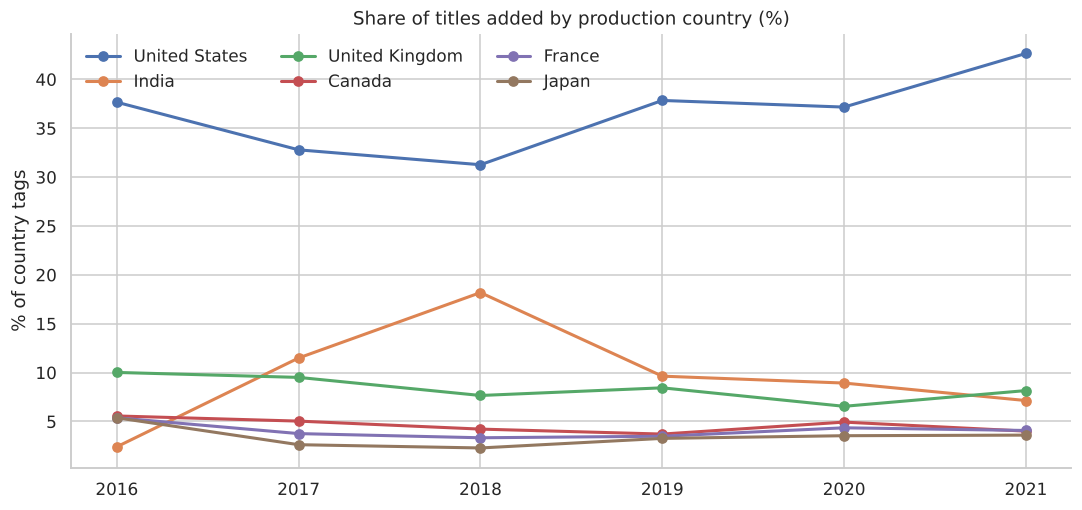

country,United States,India,United Kingdom,Canada,France,Japan
year_added,,,,,,
2016,37.7,2.4,10.0,5.6,5.4,5.4
2017,32.8,11.5,9.5,5.0,3.8,2.6
2018,31.3,18.2,7.7,4.2,3.3,2.3
2019,37.8,9.6,8.4,3.7,3.5,3.3
2020,37.2,8.9,6.6,4.9,4.4,3.5
2021,42.7,7.1,8.2,4.0,4.1,3.6


In [10]:
top6 = CT.country.value_counts().head(6).index
r = CT[CT.year_added.between(2016, 2021)]
share = (pd.crosstab(r.year_added, r.country, normalize='index')[top6] * 100)
share.index = share.index.astype(int)
ax = share.plot(marker='o', figsize=(10, 4.8), lw=2)
ax.set_title('Share of titles added by production country (%)'); ax.set_ylabel('% of country tags'); ax.set_xlabel('')
ax.legend(title='', ncol=3, frameon=False)
save('06_country_mix_over_time'); plt.show()
share.round(1)

**Takeaway:** The US share dipped from ~38% (2016) to ~31% (2018) as Netflix internationalised, then recovered to ~43% in 2021. India spiked from 2% (2016) to 18% (2018) and has since cooled to 7%.

### Viz 7 — Top producing countries (interactive)

In [11]:
cc = CT.country.value_counts().head(15).reset_index(); cc.columns = ['country', 'titles']
fig = px.bar(cc.sort_values('titles'), x='titles', y='country', orientation='h', text='titles',
             color_discrete_sequence=[RED], title='Top 15 production countries by titles')
fig.update_layout(height=520, template='plotly_white', yaxis_title='', xaxis_title='Titles')
fig.write_html('../images/07_top_countries.html', include_plotlyjs='cdn'); fig.show()

**Takeaway:** The US (3,690), India (1,046) and UK (806) account for the bulk of the catalog; Canada, France, Japan, Spain and South Korea form a strong second tier.

### Viz 8 — How movie length has trended

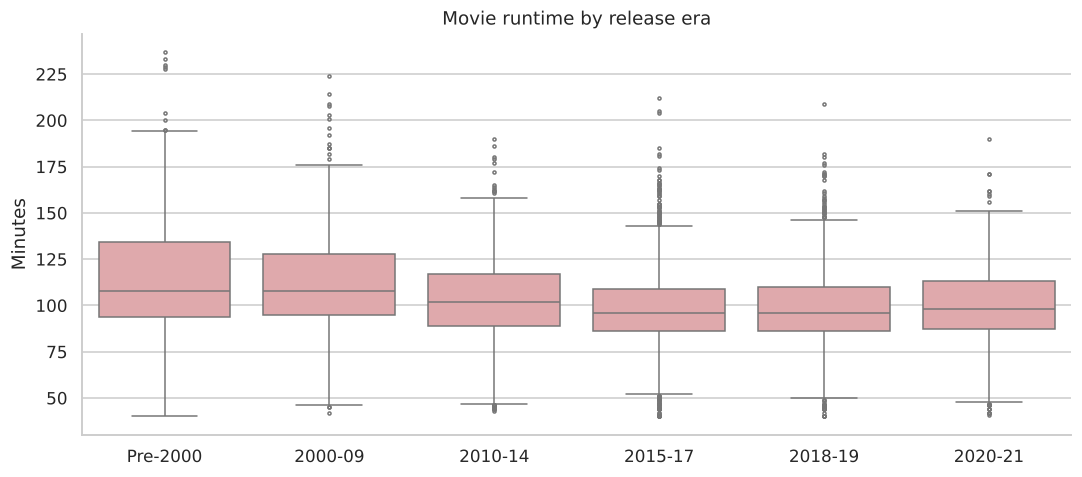

,count,mean,median
release_era,,,
Pre-2000,468,116.0,108.0
2000-09,673,112.6,108.0
2010-14,939,102.7,102.0
2015-17,1789,97.7,96.0
2018-19,1351,97.3,96.0
2020-21,738,98.5,98.0


In [12]:
m = df[(df.type=='Movie') & df.duration_min.between(40, 240)]
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=m, x='release_era', y='duration_min', color='#e8a0a4', fliersize=2)
plt.title('Movie runtime by release era'); plt.xlabel(''); plt.ylabel('Minutes')
save('08_movie_duration_trend'); plt.show()
m.groupby('release_era', observed=True).duration_min.agg(['count','mean','median']).round(1)

**Takeaway:** Mean runtime fell from ~116 min (pre-2000) to ~98 min for titles released since 2015 (-18 min). Most of the drop happened by 2015-17 and has since plateaued around 97-98 min, so ~95-100 min is the current norm.

### Viz 9 — TV shows: season counts

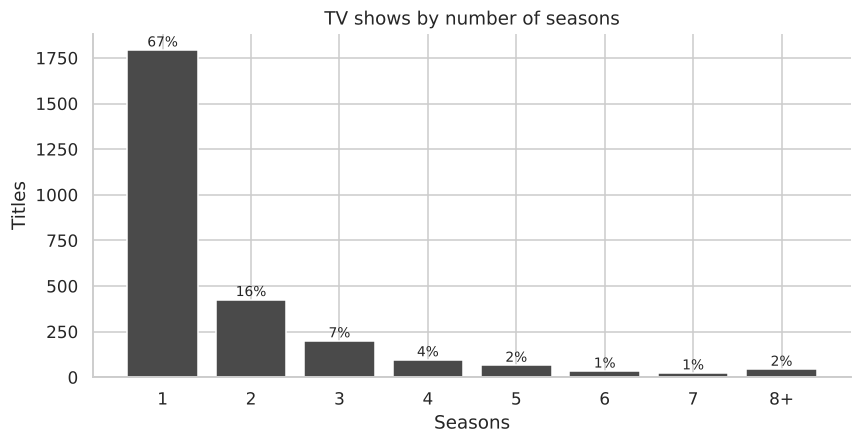

In [13]:
t = df[df.type=='TV Show']
s = t.n_seasons.clip(upper=8).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(s.index.astype(int).astype(str).str.replace('8', '8+'), s.values, color=PAL['TV Show'])
ax.set_title('TV shows by number of seasons'); ax.set_xlabel('Seasons'); ax.set_ylabel('Titles')
for i, v in enumerate(s.values): ax.text(i, v+20, f'{v/len(t):.0%}', ha='center', fontsize=9)
save('09_tv_seasons'); plt.show()

**Takeaway:** 67% of TV shows have only one season and just ~10% reach 4+ seasons — most series either run short (limited series) or are cancelled early. Renewal discipline matters.

### Viz 10 — International co-productions & release-to-Netflix lag

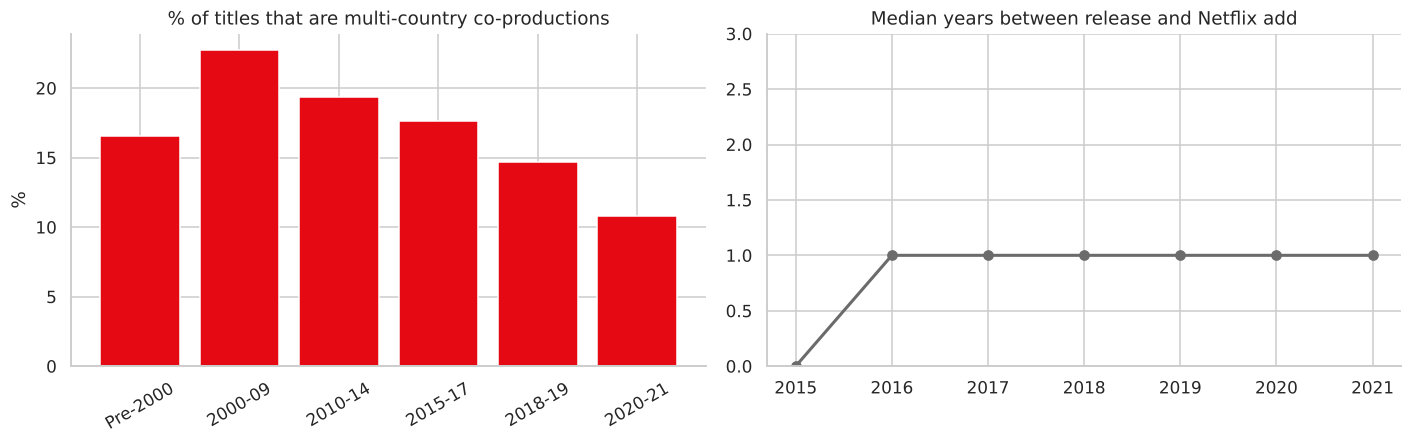

release_era
Pre-2000    16.5
2000-09     22.8
2010-14     19.4
2015-17     17.6
2018-19     14.7
2020-21     10.8
Name: is_coprod, dtype: float64


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cp = df[df.country!='Unknown'].groupby('release_era', observed=True).is_coprod.mean() * 100
ax[0].bar(cp.index.astype(str), cp.values, color=RED); ax[0].set_title('% of titles that are multi-country co-productions')
ax[0].set_ylabel('%'); ax[0].tick_params(axis='x', rotation=30)
lag = df[df.year_added.between(2015, 2021)].groupby('year_added').lag_years.median()
ax[1].plot(lag.index.astype(int), lag.values, marker='o', color=GREY, lw=2)
ax[1].set_title('Median years between release and Netflix add'); ax[1].set_ylim(0, 3)
save('10_coproduction_and_lag'); plt.show()
print(cp.round(1))

**Takeaway:** Co-productions fell from ~23% of titles (2000s) to ~11% (2020–21) — newer content is increasingly *single-country / local-origin*. The median lag between release and Netflix is only 1 year, showing most of the catalog is recent content.

### Bonus — India deep dive (largest non-US market in the catalog)

India titles by type:
type
Movie      962
TV Show     84
Name: count, dtype: int64


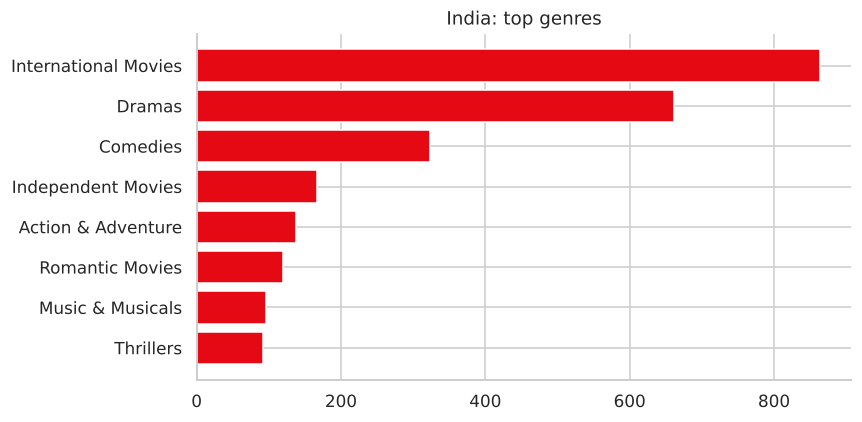

In [15]:
ind = CT[CT.country=='India'].merge(genres, on='show_id')
print('India titles by type:'); print(CT[CT.country=='India'].type.value_counts())
top = ind.genre.value_counts().head(8).sort_values()
plt.figure(figsize=(8, 4)); plt.barh(top.index, top.values, color=RED); plt.title('India: top genres')
save('11_india_genres'); plt.show()

India is 92% movies (962) vs only 84 TV shows (8% TV). South Korea is 74% TV and Japan 63% TV — a clear **series gap** for India.

## 4. Strategy insights

| # | Insight | Evidence | Recommendation |
|---|---|---|---|
| 1 | Series are gaining and most of them stop at season 1 | TV share of additions 25%→34% (2018→2021); 67% of shows have 1 season, ~10% reach 4+ | Greenlight fewer, deeper series with renewal potential |
| 2 | International content is the growth engine | International Movies/TV are the #1 genres; US is only 37% of country tags | Invest in local-language series: South Korea, Japan, UK, Spanish-language |
| 3 | India has a series gap | 962 movies vs 84 shows (8% TV) vs Korea 74% TV | Commission Indian-language series (crime, drama, romance) |
| 4 | Movie runtimes have settled at ~95-100 min | ~116 min pre-2000 → ~98 min since 2015, flat since | Brief originals at 90–100 min |

A fuller write-up is in `memo/content_strategy_memo.md`.